# Step 18 — a KNHANES-trained risk score as an extra NHANES feature (stacking)

Step 11 put the KNHANES people into the NHANES training set and AUROC did not change. Here KNHANES is used differently: a model is trained **only on KNHANES**, and its predicted risk for each NHANES person becomes one more feature of the NHANES model.

**Design**

1. **Korean model.** Elastic net and XGBoost on all 10,518 KNHANES 2014 + 2016 people, the 114 features KNHANES has in both years, outcome PHQ-9 ≥ 10. Hyper-parameters by leave-one-year-out (train 2014 → validate 2016 and the reverse), same grids as step 1.
2. **Score.** The two Korean models predict every NHANES person; the logits become two features, `kr_score_logreg` and `kr_score_xgb`. The Korean models never see an NHANES label, so the score is a fixed function of each person's own features and cannot leak the test labels.
3. **NHANES model.** The usual LOCO over the 7 NHANES cycles with inner LOCO tuning (step 1), with the two scores added to the features. Two feature sets:
   - `full`: all 317 features + 2 scores, compared with step 1 (0.874 / 0.871);
   - `k114`: the 114 shared features + 2 scores, compared with step 9 k114 (0.834 / 0.833) and step 11 (KNHANES added as rows).

**Output:** `$NHANES_WORK/modeling/step18_knhanes_stacking/` (`korean_model.json`, `kr_scores.csv.gz`, and one folder per feature set with the step 1 files).

`RUN = True` retrains (Korean models a few minutes; `full` about 2 hours and `k114` about 40 minutes on 4 threads) and needs the KNHANES files (`KNHANES_DATA`). `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step18_knhanes_stacking
QUICK = False  # with RUN: one outer fold, smallest grids
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step18_knhanes_stacking"
REFS = {"full": RESULTS / "step1", "k114": RESULTS / "step9_knhanes_features" / "k114"}
STEP11 = RESULTS / "step11_knhanes_augment"
mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv")
K114 = list(mapping.feature[mapping.years == "both"])
SCORES = ["kr_score_logreg", "kr_score_xgb"]

## Korean model and the score for every NHANES person

In [2]:
if RUN:
    from nhanes import knhanes
    from nhanes.loco import (FEAT, LOGREG_GRID, NOT_FEATURES, XGB_GRID, fit_logreg, fit_xgb, grid,
                             logreg_matrix, run_loco, tune)
    OUT.mkdir(parents=True, exist_ok=True)
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    kr = knhanes.load()
    kr = kr.assign(SEQN=np.nan, SDMVPSU=np.nan, SDMVSTRA=np.nan, WTINT2YR=np.nan,
                   WTMEC2YR=kr.wt_itvex)[NOT_FEATURES + K114].reset_index(drop=True)
    years = sorted(kr.cycle.unique())
    print(f"KNHANES {len(kr):,} rows ({kr.depression.sum()} with PHQ-9 >= 10), years {years}; "
          f"NHANES {len(data):,} rows")
    g = {"logreg": grid(LOGREG_GRID), "xgboost": grid(XGB_GRID)}
    if QUICK:
        g = {k: v[:1] for k, v in g.items()}
    Xkr, Xnh = kr[K114], data[K114]
    info = {}
    p, auc = tune("logreg", kr, years, dic, g["logreg"])
    A, B = logreg_matrix(Xkr, Xnh, dic)
    prob_lr = fit_logreg(A, kr.depression, p).predict_proba(B)[:, 1]
    info["logreg"] = {**p, "leave_one_year_out_auroc": round(auc, 4)}
    p, auc = tune("xgboost", kr, years, dic, g["xgboost"])
    fit_p = {k: v for k, v in p.items() if k != "n_estimators"}
    prob_xgb = fit_xgb(Xkr, kr.depression, None, None, fit_p, n_estimators=p["n_estimators"]).predict_proba(Xnh)[:, 1]
    info["xgboost"] = {**p, "leave_one_year_out_auroc": round(auc, 4)}
    logit = lambda q: np.log(np.clip(q, 1e-6, 1 - 1e-6) / (1 - np.clip(q, 1e-6, 1 - 1e-6)))
    scores = pd.DataFrame({"SEQN": data.SEQN, "cycle": data.cycle, "depression": data.depression,
                           "kr_score_logreg": logit(prob_lr), "kr_score_xgb": logit(prob_xgb)})
    scores.to_csv(OUT / "kr_scores.csv.gz", index=False)
    (OUT / "korean_model.json").write_text(json.dumps(info, indent=1))

    data = pd.concat([data, scores[SCORES]], axis=1)
    feats = {"k114": K114, "full": [c for c in data if c not in NOT_FEATURES + SCORES]}
    for name in ["k114", "full"]:
        cols = NOT_FEATURES + feats[name] + SCORES
        print(f"\n=== {name}: {len(feats[name])} features + 2 Korean scores ===", flush=True)
        run_loco(data[cols], dic, OUT / name, QUICK,
                 title=f"leave-one-cycle-out on NHANES, {name} features + KNHANES-trained risk scores")

KNHANES 10,518 rows (693 with PHQ-9 >= 10), years ['KNHANES 2014', 'KNHANES 2016']; NHANES 33,498 rows



=== k114: 114 features + 2 Korean scores ===


2005-06 logreg: AUROC 0.844  {'C': 0.1, 'l1_ratio': 1.0}  13.1 min


2005-06 xgboost: AUROC 0.843  {'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 219}  14.6 min


2007-08 logreg: AUROC 0.846  {'C': 0.01, 'l1_ratio': 0.0}  14.0 min


2007-08 xgboost: AUROC 0.841  {'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 150}  9.3 min


... (22 outputs left out)

2015-16 xgboost: AUROC 0.880  {'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 268}  7.2 min


2017-18 logreg: AUROC 0.858  {'C': 0.01, 'l1_ratio': 0.5}  23.3 min


2017-18 xgboost: AUROC 0.855  {'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 215}  3.7 min


leave-one-cycle-out on NHANES, full features + KNHANES-trained risk scores

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.873  0.011          0.876  0.017  0.478  0.038  0.137  0.005
xgboost  0.871  0.011          0.876  0.016  0.477  0.033  0.132  0.004

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.872
xgboost    0.870

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.892           0.901  0.502  0.128 3975       0.062     29.4
xgboost    2005-06  0.889           0.899  0.492  0.127 3975       0.062     10.8
 logreg    2007-08  0.877           0.873  0.519  0.137 5104       0.098     24.7
xgboost    2007-08  0.873           0.869  0.509  0.136 5104       0.098   

## Results

How good is the Korean model on its own? Leave-one-year-out AUROC inside KNHANES, and the AUROC of the score itself on each NHANES cycle (no NHANES training at all; the same idea as step 10, in the other direction).

In [3]:
from sklearn.metrics import roc_auc_score  # noqa: E402

print(json.dumps(json.loads((OUT / "korean_model.json").read_text()), indent=1))
scores = pd.read_csv(OUT / "kr_scores.csv.gz")
display(scores.groupby("cycle").apply(lambda d: pd.Series({s: roc_auc_score(d.depression, d[s]) for s in SCORES}))
        .round(3).assign(n=scores.groupby("cycle").size()))
print("all NHANES pooled:", {s: round(roc_auc_score(scores.depression, scores[s]), 3) for s in SCORES})

{
 "logreg": {
  "C": 0.1,
  "l1_ratio": 1.0,
  "leave_one_year_out_auroc": 0.8225
 },
 "xgboost": {
  "max_depth": 3,
  "min_child_weight": 1,
  "n_estimators": 114,
  "leave_one_year_out_auroc": 0.8238
 }
}


,kr_score_logreg,kr_score_xgb,n
cycle,,,
2005-06,0.822,0.821,3975
2007-08,0.832,0.817,5104
2009-10,0.800,0.804,5222
2011-12,0.826,0.822,4594
2013-14,0.816,0.814,4995
2015-16,0.818,0.813,4829
2017-18,0.781,0.786,4779


all NHANES pooled: {'kr_score_logreg': 0.813, 'kr_score_xgb': 0.811}


NHANES model with the two scores, against the same design without them, test cycle by test cycle.


##### full #####


leave-one-cycle-out on NHANES, full features + KNHANES-trained risk scores

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.873  0.011          0.876  0.017  0.478  0.038  0.137  0.005
xgboost  0.871  0.011          0.876  0.016  0.477  0.033  0.132  0.004

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.872
xgboost    0.870

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.892           0.901  0.502  0.128 3975       0.062     29.4
xgboost    2005-06  0.889           0.899  0.492  0.127 3975       0.062     10.8
 logreg    2007-08  0.877           0.873  0.519  0.137 5104       0.098     24.7
xgboost    2007-08  0.873           0.869  0.509  0.136 5104       0.098   

auroc         auprc         brier       
                                      mean    std   mean    std   mean    std
model   training                                                             
logreg  without score (step1)        0.874  0.011  0.481  0.036  0.137  0.007
xgboost without score (step1)        0.871  0.010  0.481  0.032  0.129  0.005
logreg  with Korean score (step 18)  0.873  0.011  0.478  0.038  0.137  0.005
xgboost with Korean score (step 18)  0.871  0.011  0.477  0.033  0.132  0.004

model,elastic net,XGBoost
test_cycle,,
2005-06,-0.0020,0.0009
2007-08,-0.0005,-0.0012
2009-10,-0.0013,-0.0004
2011-12,-0.0002,0.0022
2013-14,0.0005,0.0045
2015-16,0.0008,0.0009
2017-18,-0.0022,-0.0058


full elastic net: mean change -0.0007 (min -0.0022, max +0.0008); better in 2 of 7 cycles
full XGBoost: mean change +0.0002 (min -0.0058, max +0.0045); better in 4 of 7 cycles


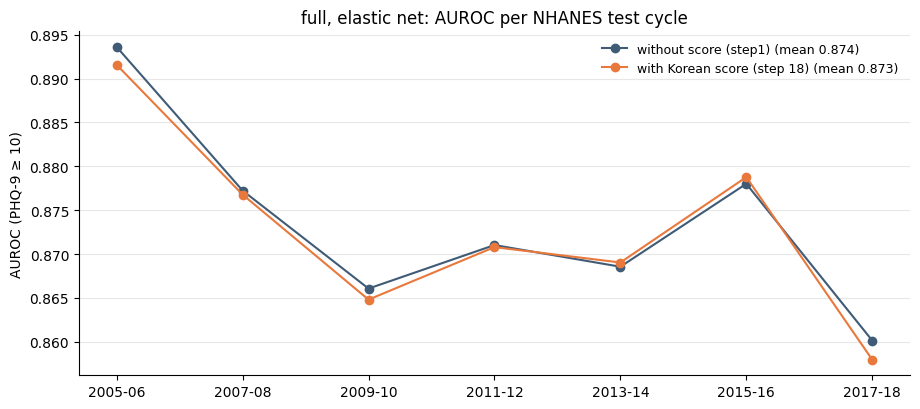

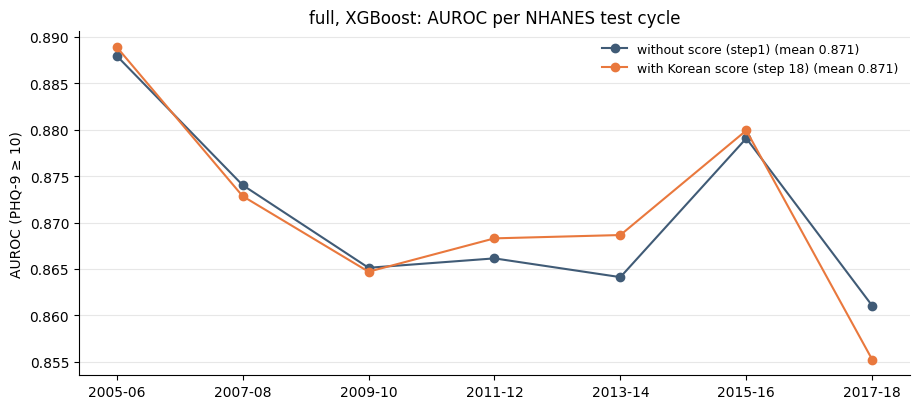


##### k114 #####
leave-one-cycle-out on NHANES, k114 features + KNHANES-trained risk scores

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.833  0.013          0.837  0.016  0.389  0.033  0.159  0.005
xgboost  0.831  0.012          0.834  0.014  0.385  0.031  0.156  0.005

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.833
xgboost    0.830

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.844           0.856  0.386  0.152 3975       0.062     13.1
xgboost    2005-06  0.843           0.850  0.399  0.151 3975       0.062     14.6
 logreg    2007-08  0.846           0.850  0.424  0.158 5104       0.098     14.0
xgboost    2007-08  0.841           0.841  0.414  0.164 5

auroc         auprc         brier       
                                      mean    std   mean    std   mean    std
model   training                                                             
logreg  without score (k114)         0.834  0.013  0.389  0.036  0.160  0.005
xgboost without score (k114)         0.833  0.011  0.392  0.030  0.153  0.005
logreg  with Korean score (step 18)  0.833  0.013  0.389  0.033  0.159  0.005
xgboost with Korean score (step 18)  0.831  0.012  0.385  0.031  0.156  0.005
logreg  KNHANES as rows (step 11)    0.834  0.014  0.387  0.037  0.168  0.004
xgboost KNHANES as rows (step 11)    0.833  0.011  0.391  0.031  0.160  0.004

model,elastic net,XGBoost
test_cycle,,
2005-06,0.0004,0.0004
2007-08,-0.0028,-0.0030
2009-10,-0.0031,-0.0054
2011-12,-0.0016,-0.0022
2013-14,-0.0013,-0.0004
2015-16,0.0016,-0.0005
2017-18,-0.0004,-0.0044


k114 elastic net: mean change -0.0010 (min -0.0031, max +0.0016); better in 2 of 7 cycles
k114 XGBoost: mean change -0.0022 (min -0.0054, max +0.0004); better in 1 of 7 cycles


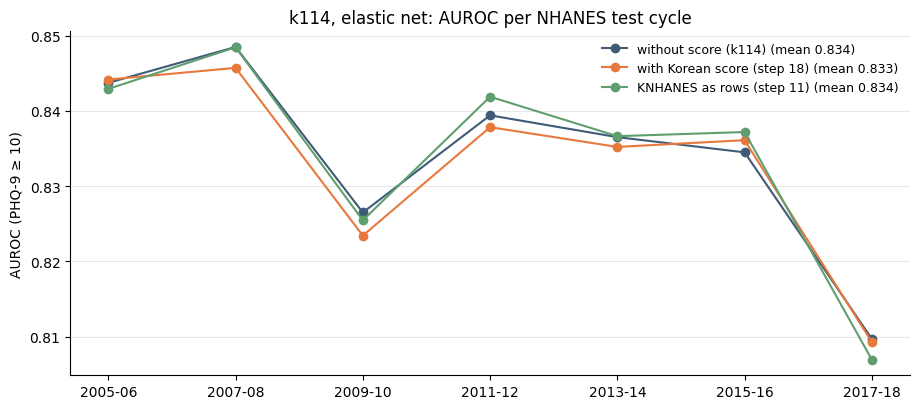

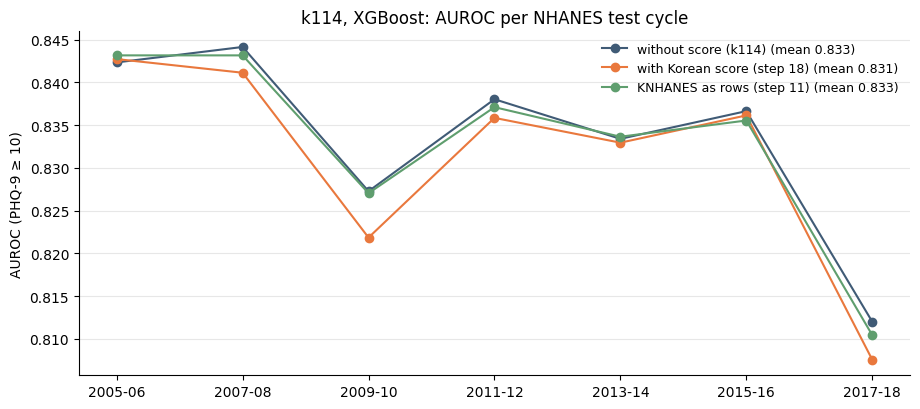

In [4]:
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
for name, ref in REFS.items():
    print(f"\n##### {name} #####")
    print((OUT / name / "report.txt").read_text())
    runs = {f"without score ({ref.name})": ref, "with Korean score (step 18)": OUT / name}
    if name == "k114":
        runs["KNHANES as rows (step 11)"] = STEP11
    met = pd.concat([pd.read_csv(p / "metrics.csv").assign(training=k) for k, p in runs.items()])
    cycles = sorted(set.intersection(*[set(g.test_cycle) for _, g in met.groupby("training")]))
    met = met[met.test_cycle.isin(cycles)]
    display(met.groupby(["model", "training"], sort=False)[["auroc", "auprc", "brier"]].agg(["mean", "std"]).round(3))
    piv = met.pivot_table(index=["model", "test_cycle"], columns="training", values="auroc")
    diff = (piv["with Korean score (step 18)"] - piv[f"without score ({ref.name})"]).rename("AUROC change")
    display(diff.unstack("model").rename(columns=NAMES).round(4))
    for model, d in diff.groupby(level="model"):
        print(f"{name} {NAMES[model]}: mean change {d.mean():+.4f} (min {d.min():+.4f}, max {d.max():+.4f}); "
              f"better in {(d > 0).sum()} of {len(d)} cycles")
    for model in NAMES:
        m = met[met.model == model].drop(columns="model").rename(columns={"training": "model"})
        plots.per_split_auroc(m, title=f"{name}, {NAMES[model]}: AUROC per NHANES test cycle")
        plots.show()